# DSA4213 Assignment 1, Part I: Language model training and comparison

In this notebook I train four next-word language models on WikiText-2 with the same vocabulary: an interpolated trigram, an RNN, an LSTM and a Transformer. I then compare their test perplexity, training and inference cost, loss curves and generated text.

## 1. Setup

The first cell checks whether the notebook is running in Google Colab or locally. In Colab the results are saved to my Google Drive (so they survive disconnects), and locally they are saved to `./results`.

In [ ]:
import os

#Detect Google Colab or localhost
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = "/content/drive/MyDrive/DSA4213 Assignment/results"
else:
    SAVE_DIR = "results"          # a local folder next to the notebook

os.makedirs(SAVE_DIR, exist_ok=True)
# When running locally, reuse the timings/features saved from my Colab (T4) run instead of
# re-measuring them on a slower machine. In Colab everything is measured again.
REUSE_SAVED = not IN_COLAB

print("Running in Colab:", IN_COLAB, "| Saving to:", SAVE_DIR, "| Reusing saved results:", REUSE_SAVED)

Mounted at /content/drive
Running in Colab: True | Saving to: /content/drive/MyDrive/DSA4213 Assignment/results | Reusing saved results: False


In [ ]:
#import, random seed and GPU
%pip install -q datasets

import random, math, time
from collections import Counter
import numpy as np
import torch
from datasets import load_dataset

SEED = 42 #fixes the randomness so every run gives the same results (for reproducibility)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


In [ ]:
#load wikitext-2
ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

print(ds)

for i in range(1, 8):
    print(repr(ds["train"][i]["text"]))


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
' = Valkyria Chronicles III = \n'
''
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " 

In [ ]:
#tokenize (split text into words)
def tokenize_split(split):
    tokens = []
    for line in ds[split]["text"]:
        line = line.strip().lower()
        if line == "":
            continue                     # skip empty lines
        tokens.extend(line.split())      # split on whitespace
        tokens.append("<eos>")           # mark the end of each line
    return tokens

train_tokens = tokenize_split("train")
val_tokens   = tokenize_split("validation")
test_tokens  = tokenize_split("test")

print(len(train_tokens), len(val_tokens), len(test_tokens))
print(train_tokens[:30])


2075677 216347 244102
['=', 'valkyria', 'chronicles', 'iii', '=', '<eos>', 'senjō', 'no', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'of', 'the', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'to']


In [ ]:
#build the vocabulary (from train only) and convert words into IDs
MIN_FREQ = 3 #keep words that appear at least 3 times in train
counts = Counter(train_tokens)

itos = ["<unk>", "<eos>"] + sorted(w for w, c in counts.items() if c >= MIN_FREQ and w != "<eos>") #index-to-string, a list to match each word to their position in the list
stoi = {w: i for i, w in enumerate(itos)} #string-to-index, a dictionary built from itos that goes the other way
V = len(itos)
print("Vocab size:", V)

def encode(tokens):
    unk = stoi["<unk>"]
    return [stoi.get(w, unk) for w in tokens]

train_ids = encode(train_tokens)
val_ids   = encode(val_tokens)
test_ids  = encode(test_tokens)

#oov rate = out of vocab rate is the percentage of words in a piece of text that are not in the vocabulary so they are replaced with <unk>
for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    print(f"{name}: {len(ids)} tokens, OOV rate = {ids.count(0)/len(ids):.2%}")


Vocab size: 29572
train: 2075677 tokens, OOV rate = 2.25%
val: 216347 tokens, OOV rate = 4.72%
test: 244102 tokens, OOV rate = 5.62%


In [ ]:
# A piece of training text as words, then as numbers
print(train_tokens[100:120])
print(train_ids[100:120])

# Turn the numbers back into words (rare words show up as <unk>)
print([itos[i] for i in train_ids[100:120]])

# Most common words
print(counts.most_common(15))


['"', ',', 'a', 'penal', 'military', 'unit', 'serving', 'the', 'nation', 'of', 'gallia', 'during', 'the', 'second', 'europan', 'war', 'who', 'perform', 'secret', 'black']
[3, 79, 1433, 19909, 17425, 27808, 24056, 26651, 18228, 18962, 11619, 9095, 26651, 23837, 10001, 28586, 28876, 19981, 23844, 4103]
['"', ',', 'a', 'penal', 'military', 'unit', 'serving', 'the', 'nation', 'of', 'gallia', 'during', 'the', 'second', 'europan', 'war', 'who', 'perform', 'secret', 'black']
[('the', 130768), (',', 99913), ('.', 73388), ('of', 57032), ('and', 50735), ('in', 44982), ('to', 39522), ('a', 36156), ('=', 29570), ('"', 28309), ('<eos>', 23767), ('was', 21008), ('@-@', 16906), ('on', 15141), ('as', 15058)]


**Why is the OOV rate higher for val/test than for train?**

I built the vocabulary from the training split only. In train, a word only becomes `<unk>` if it appears fewer than 3 times. The val/test splits are different Wikipedia articles, so they contain names, places and terms that never appear in train at all, and these can't be in the vocabulary.

So val/test have the rare words plus completely new words, which gives about 5% OOV compared to 2.25% for train. This is expected because the vocabulary never saw the val/test data (no leakage).

## 2. The n-gram model

The trigram model predicts the next word by counting what followed the previous 2 words in the training text:

P("mat" | "on the") = count("on the mat") / count("on the")

The problem is that most 3-word sequences in the test set never appear in train, so their probability would be 0 and the perplexity would be infinite. To fix this I interpolate three estimates:

P(w) = λ3·P_trigram + λ2·P_bigram + λ1·P_unigram, where λ1 + λ2 + λ3 = 1

The unigram uses add-one smoothing so it is never 0, and I choose the λ values on the validation set.

I evaluate every model in this assignment the same way. Cross-entropy (CE) is the average of −log P(correct next word) over the test set, and perplexity is exp(CE). Lower is better. Guessing uniformly over the 29,572-word vocabulary would give a perplexity of 29,572.

In [ ]:
#count n-gram (training)

t0 = time.time()

uni = Counter(train_ids)                                               # count(w)
bi  = Counter(zip(train_ids[:-1], train_ids[1:]))                      # count(u, w)
tri = Counter(zip(train_ids[:-2], train_ids[1:-1], train_ids[2:]))     # count(t, u, w)

ctx1 = Counter(train_ids[:-1])                                         # count(u) as a context
ctx2 = Counter(zip(train_ids[:-2], train_ids[1:-1]))                   # count(t, u) as a context
N = len(train_ids)

ngram_train_time = time.time() - t0
print(f"Counting took {ngram_train_time:.1f}s")
print(f"Unique bigrams: {len(bi):,}   Unique trigrams: {len(tri):,}")

# Show the most common trigrams as words
for (t, u, w), c in tri.most_common(5):
    print(itos[t], itos[u], itos[w], "→", c)


Counting took 6.2s
Unique bigrams: 596,568   Unique trigrams: 1,388,742
= = = → 5956
<eos> = = → 5582
= = <eos> → 5582
. <eos> = → 5025
. <eos> the → 1882


There are 597k different bigrams and 1.39M different trigrams in the 2M training words, and most of them only appear once.

The most common trigrams are all `=` signs. This is because WikiText writes section headings like `= = Gameplay = =`, and there are thousands of them. The first "real" trigram is `. <eos> the`, where a line ends and the next one starts with "the". I kept the heading markup as part of the text. Every model sees the same data, so this doesn't affect the fairness of the comparison.

In [ ]:
#probability functions
def ngram_component_probs(ids):
    """For each position, compute the unigram, bigram and trigram probability of the true next word."""
    p1, p2, p3 = [], [], []
    for i in range(2, len(ids)):
        t, u, w = ids[i-2], ids[i-1], ids[i]          # two previous words -> target word
        p1.append((uni[w] + 1) / (N + V))                                    # add-1 smoothed, never 0
        p2.append(bi[(u, w)] / ctx1[u] if ctx1[u] > 0 else 0.0)
        p3.append(tri[(t, u, w)] / ctx2[(t, u)] if ctx2[(t, u)] > 0 else 0.0)
    return np.array(p1), np.array(p2), np.array(p3)

def interpolated_ce(lambdas, probs):
    l1, l2, l3 = lambdas
    p1, p2, p3 = probs
    p = l1 * p1 + l2 * p2 + l3 * p3
    return -np.mean(np.log(p))                         # average cross-entropy


In [ ]:
#choose λ values on the validation set

val_probs = ngram_component_probs(val_ids)

best_ce, best_lambdas = float("inf"), None
grid = [round(x, 2) for x in np.arange(0.05, 1.0, 0.05)]
for l1 in grid:
    for l2 in grid:
        l3 = round(1 - l1 - l2, 2)
        if l3 < 0:
            continue
        ce = interpolated_ce((l1, l2, l3), val_probs)
        if ce < best_ce:
            best_ce, best_lambdas = ce, (l1, l2, l3)

print("Best lambdas (uni, bi, tri):", best_lambdas)
print(f"Validation CE = {best_ce:.3f}   PPL = {math.exp(best_ce):.1f}")


Best lambdas (uni, bi, tri): (np.float64(0.3), np.float64(0.55), np.float64(0.15))
Validation CE = 5.692   PPL = 296.4


The best weights are 30% unigram, 55% bigram and only 15% trigram.

The trigram gets a small weight because of data sparsity. With only 2M words, most 3-word sequences in the validation text never appeared in train, so the trigram estimate is usually 0 or based on just 1-2 examples. Bigrams are seen much more often, so they are more reliable, and the unigram is the fallback when the context has never been seen.

A validation perplexity of 296.4 means the model is about as unsure as if it were picking between 296 equally likely words (compared to 29,572 for random guessing).

In [ ]:
#final score and timing
import json

t0 = time.time()
test_probs = ngram_component_probs(test_ids)
test_ce = interpolated_ce(best_lambdas, test_probs)
ngram_infer_time = time.time() - t0

# keep the timings from my Colab run (read before results.json is overwritten below)
saved_results = {}
if REUSE_SAVED and os.path.exists(os.path.join(SAVE_DIR, "results.json")):
    with open(os.path.join(SAVE_DIR, "results.json")) as f:
        saved_results = json.load(f)
    ngram_train_time = saved_results["ngram"]["train_time_s"]
    ngram_infer_time = saved_results["ngram"]["infer_time_s"]

n_test = len(test_ids) - 2
results = {"ngram": {
    "test_ce": float(test_ce),
    "test_ppl": math.exp(test_ce),
    "lambdas": best_lambdas,
    "train_time_s": ngram_train_time,
    "infer_time_s": ngram_infer_time,
    "throughput_tok_per_s": n_test / ngram_infer_time,
    "size_num_ngrams": len(uni) + len(bi) + len(tri),
}}
print(json.dumps(results["ngram"], indent=2))

with open(os.path.join(SAVE_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)


{
  "test_ce": 5.625879135085562,
  "test_ppl": 277.51615149701195,
  "lambdas": [
    0.3,
    0.55,
    0.15
  ],
  "train_time_s": 6.187946081161499,
  "infer_time_s": 0.5262413024902344,
  "throughput_tok_per_s": 463855.64729505405,
  "size_num_ngrams": 2014882
}


Results for the n-gram:
* Test perplexity is 277.5 (test CE 5.626, and exp(5.626) = 277.5). This is the baseline the neural models need to beat.
* Training took 3.6 s, since it is only counting.
* Scoring the whole test set took 0.49 s, about 497k tokens/s on the CPU (just dictionary lookups).
* The model stores about 2.0M counts, which I use as its "model size".

The test perplexity is a bit lower than validation (277.5 vs 296.4). The two splits are different articles and some are easier to predict than others. The timings are single measurements and change a little between runs.

**Why does λ1 (the unigram weight) have to stay above 0?**

Take the phrase "... the purple giraffe" in the test set:
* Trigram: "the purple giraffe" never appears in train, so P = 0.
* Bigram: "purple giraffe" never appears in train, so P = 0.
* Unigram: "giraffe" gets (count + 1) / (N + V), which can never be 0 because of the +1.

If λ1 = 0 the mixed probability is 0, and −log(0) is infinite, so one unseen word would make the whole test perplexity infinite. Keeping λ1 above 0 means every word always gets some probability. The add-one unigram is the smoothing part of the model.

## 3. Preparing the data for the neural models

For the neural models I cut the token stream into 32 parallel streams (the batch size) and feed the model 64 tokens at a time from each stream (the context length). So each training step sees a 32 × 64 block of tokens.

The target is the input shifted by one position:

`input  x: the   cat   sat   on    the`

`target y: cat   sat   on    the   mat`

At each position the model has read the words up to that point and has to predict the next one.

In [ ]:
#settings and batchify
BATCH_SIZE = 32       # number of parallel text streams per step
BPTT = 64             # context length: words per chunk
EVAL_BATCH_SIZE = 32

def batchify(ids, bsz):
    """Cut a long list of IDs into bsz equal rows -> tensor of shape (bsz, n)."""
    data = torch.tensor(ids, dtype=torch.long)
    n = len(data) // bsz                 # length of each row
    data = data[: n * bsz]               # drop leftover words that don't fill a full row
    return data.view(bsz, n).to(device)  # reshape long list into a table with 32 rows. row 0 is the 1/32 of the text, row 1 is the next 1/32 and so on. each row is continuous text. then move to GPU

train_data = batchify(train_ids, BATCH_SIZE)
val_data   = batchify(val_ids, EVAL_BATCH_SIZE)
test_data  = batchify(test_ids, EVAL_BATCH_SIZE)

print("train_data shape:", train_data.shape)
print("val_data shape:  ", val_data.shape)
print("test_data shape: ", test_data.shape)


train_data shape: torch.Size([32, 64864])
val_data shape:   torch.Size([32, 6760])
test_data shape:  torch.Size([32, 7628])


The 2,075,677 training tokens become a table with 32 rows and 64,864 columns. Each row is one continuous 1/32 slice of the training text (32 × 64,864 = 2,075,648, so the last 29 tokens that don't fill a row are dropped). Validation (32 × 6,760) and test (32 × 7,628) are cut the same way, and the 32 rows are processed in parallel on the GPU.

In [ ]:
#getting one chunk
def get_batch(data, i):
    """Take columns i..i+BPTT as input, and the same shifted by 1 as target."""
    seq_len = min(BPTT, data.size(1) - 1 - i)   #handles the end of the data, where fewer than 64 words may be left
    x = data[:, i : i + seq_len]                #takes all 32 rows and 64 columns starting at column i
    y = data[:, i + 1 : i + 1 + seq_len]        #same thing as x but shifted one column to the right: the next word at every position
    return x, y

# Check it: decode row 0 of the first chunk
x, y = get_batch(train_data, 0)
print("x shape:", x.shape, " y shape:", y.shape)
print("INPUT :", " ".join(itos[t] for t in x[0, :12].tolist()))
print("TARGET:", " ".join(itos[t] for t in y[0, :12].tolist()))


x shape: torch.Size([32, 64])  y shape: torch.Size([32, 64])
INPUT : = valkyria chronicles iii = <eos> senjō no valkyria 3 : unrecorded
TARGET: valkyria chronicles iii = <eos> senjō no valkyria 3 : unrecorded chronicles


`get_batch(train_data, 0)` takes the first 64 columns, which is one training step (32 rows × 64 tokens). One epoch is about 1,013 steps (64,864 / 64).

In the printed row the target is the input shifted one word to the left, so each position pairs the words read so far with the next word:

| Position | Read so far | Has to predict |
|---|---|---|
| 1 | `=` | `valkyria` |
| 2 | `= valkyria` | `chronicles` |
| 3 | `= valkyria chronicles` | `iii` |

So every 64-token window gives 64 targets, and each step gives 32 × 64 = 2,048 targets.

Two design decisions:
* There is no padding. All windows come from continuous text, so every target is a real token and no padding goes into the loss.
* Each 64-token window is processed on its own (I don't carry the hidden state over to the next window). This means all three neural models see at most 64 previous tokens, while the n-gram sees 2.

## 4. RNN/LSTM models and the training loop

An RNN reads the tokens one at a time from left to right and keeps a hidden state that it updates after each token. The prediction for the next word comes from this hidden state. Since the state is rewritten at every step, information from many words back tends to fade (vanishing gradients). The LSTM has the same structure but adds gates that learn what to keep, forget and add, so it can carry information further.

```
word IDs (32x64)
   -> Embedding: each word ID becomes a 100-d vector (random start, trainable)
   -> RNN or LSTM (2 layers, hidden size 256), reading left to right
   -> Linear: 256 -> a score for each of the 29,572 words
```

In [ ]:
#settings and the model class
import torch.nn as nn

# ---- Shared hyperparameters for ALL neural models ----
EMB_DIM = 100        # matches GloVe 100d (needed for Part 2)
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT = 0.3
EPOCHS = 10
LR = 1e-3
CLIP = 1.0

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

class RecurrentLM(nn.Module):
    def __init__(self, vocab_size, cell="lstm", emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM,
                 num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        rnn_class = nn.LSTM if cell == "lstm" else nn.RNN
        self.rnn = rnn_class(emb_dim, hidden_dim, num_layers=num_layers,
                             dropout=dropout, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        emb = self.drop(self.embedding(x))   # (B, T)      -> (B, T, 100)
        out, _ = self.rnn(emb)               # (B, T, 100) -> (B, T, 256)
        return self.fc(self.drop(out))       # (B, T, 256) -> (B, T, 29572)


Notes on the model:
* The RNN and LSTM use the same class. `cell="rnn"` or `cell="lstm"` is the only difference, so the comparison only changes the recurrent cell.
* `batch_first=True` matches the (batch, time) layout from Section 3.
* Dropout of 0.3 is applied to the embeddings, between the two recurrent layers and before the output layer. It is turned off during evaluation.
* I don't pass in a starting hidden state, so every 64-token window starts from zeros.
* The input and output embeddings are not tied.

In [ ]:
criterion = nn.CrossEntropyLoss()

def count_params(model):
    return sum(p.numel() for p in model.parameters())

for cell in ["rnn", "lstm"]:
    set_seed()
    m = RecurrentLM(V, cell=cell).to(device)
    x, y = get_batch(train_data, 0)
    logits = m(x)
    loss = criterion(logits.reshape(-1, V), y.reshape(-1))
    print(f"{cell.upper():4s} | params = {count_params(m):,} | output shape = {tuple(logits.shape)} | "
          f"untrained loss = {loss.item():.3f}")

print(f"Expected untrained loss ≈ ln(V) = {math.log(V):.3f}")


RNN  | params = 10,780,436 | output shape = (32, 64, 29572) | untrained loss = 10.309
LSTM | params = 11,450,132 | output shape = (32, 64, 29572) | untrained loss = 10.289
Expected untrained loss ≈ ln(V) = 10.295


Checking the setup before training:
* `criterion` is the token-level cross-entropy, the same measure I used for the n-gram.
* `reshape(-1, V)` flattens the 32 × 64 positions into 2,048 predictions for the loss.
* An untrained model should be close to guessing uniformly, so its loss should be close to ln(29572) = 10.29. Both models are very close to this, so the setup looks right.
* Most of the parameters (92% for the LSTM, 98% for the RNN) are in the embedding (29,572 × 100) and the output layer (256 × 29,572). The LSTM's recurrent layers are exactly 4 times the size of the RNN's, because the LSTM has 4 sets of gate weights.

In [ ]:
def evaluate(model, data):
    """Average cross-entropy per token over a whole split."""
    model.eval()                                # turn dropout OFF
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():                       # no learning, just scoring
        for i in range(0, data.size(1) - 1, BPTT):
            x, y = get_batch(data, i)
            logits = model(x)
            loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            total_loss += loss.item() * y.numel()
            total_tokens += y.numel()
    return total_loss / total_tokens


`evaluate` goes through a split in 64-token windows and averages the cross-entropy over every target token. `loss.item() * y.numel()` turns each window's average back into a sum, so every token counts equally. Dropout is off and no gradients are calculated.

In [ ]:
def train_model(model, name, epochs=EPOCHS, lr=LR):
    model.to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    history = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val = float("inf")
    ckpt_path = os.path.join(SAVE_DIR, f"{name}.pt")
    starts = list(range(0, train_data.size(1) - 1, BPTT))   # start column of every chunk

    for epoch in range(1, epochs + 1):
        model.train()                                        # dropout ON
        random.shuffle(starts)                               # visit chunks in a new order each epoch
        total_loss, total_tokens = 0.0, 0
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()

        for i in starts:
            x, y = get_batch(train_data, i)
            logits = model(x)                                              # 1. predict
            loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))  # 2. measure error
            optimizer.zero_grad()
            loss.backward()                                                # 3. work out how to adjust each weight
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)       # 4. cap overly large adjustments
            optimizer.step()                                               # 5. adjust the weights
            total_loss += loss.item() * y.numel()
            total_tokens += y.numel()

        if device == "cuda": torch.cuda.synchronize()
        epoch_time = time.time() - t0
        train_loss = total_loss / total_tokens
        val_loss = evaluate(model, val_data)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(epoch_time)

        if val_loss < best_val:                              # keep the best version
            best_val = val_loss
            torch.save(model.state_dict(), ckpt_path)

        print(f"{name} | epoch {epoch:2d} | train {train_loss:.3f} (ppl {math.exp(train_loss):6.1f}) "
              f"| val {val_loss:.3f} (ppl {math.exp(val_loss):6.1f}) | {epoch_time:.1f}s")

    model.load_state_dict(torch.load(ckpt_path))             # restore best checkpoint
    with open(os.path.join(SAVE_DIR, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    return history


I use the same `train_model` function for every neural model in Parts I and II. Each step:
1. Predict the next token at every position in the window.
2. Compute the cross-entropy against the real next tokens.
3. `loss.backward()` computes the gradients.
4. Clip the gradients to a norm of 1.0 so they can't explode.
5. `optimizer.step()` updates the weights with Adam (learning rate 1e-3).

Other details:
* The order of the windows is shuffled every epoch.
* After each epoch I compute the validation loss. The train and validation losses are used for the loss curves.
* I save the checkpoint with the lowest validation loss and reload it at the end.
* I call `torch.cuda.synchronize()` before reading the clock, because GPU work runs asynchronously and the timing would otherwise be off.
* Only parameters with `requires_grad=True` go to the optimizer. This matters for the frozen embeddings in Part II (in Part I everything is trainable).

## 5. Training the RNN and LSTM

In [ ]:
#to prevent Colab disconnecting and losing variables and needing to re-run notebook, use a helper loads a finished model from Drive instead of training it

#train-or-load helper
def train_or_load(model, name):
    ckpt = os.path.join(SAVE_DIR, f"{name}.pt")
    hist = os.path.join(SAVE_DIR, f"{name}_history.json")
    if os.path.exists(ckpt) and os.path.exists(hist):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model.to(device)
        print(f"Loaded saved {name} (skipping training)")
        with open(hist) as f:
            return json.load(f)
    return train_model(model, name)


`train_or_load` loads a finished checkpoint instead of training again, because Colab sessions sometimes disconnect. The history file is only saved after training finishes, so a half-finished run is never treated as finished. To retrain from scratch, delete the `.pt` and `_history.json` files.

In [ ]:
#train the RNN
set_seed()
rnn_model = RecurrentLM(V, cell="rnn")
rnn_hist = train_or_load(rnn_model, "rnn")


Loaded saved rnn (skipping training)


In [ ]:
#train the LSTM
set_seed()
lstm_model = RecurrentLM(V, cell="lstm")
lstm_hist = train_or_load(lstm_model, "lstm")


Loaded saved lstm (skipping training)


`set_seed()` before each model makes the starting weights reproducible. I trained the RNN and LSTM in an earlier Colab session, so the cells above load their checkpoints, and the next cell prints their per-epoch training logs from the saved history files.

In [ ]:
# The RNN and LSTM were trained in an earlier session and are loaded from checkpoints above,
# so their per-epoch training logs are printed here from the saved history files.
for name in ['rnn', 'lstm']:
    with open(os.path.join(SAVE_DIR, f"{name}_history.json")) as f:
        h = json.load(f)
    for epoch, (tl, vl, et) in enumerate(zip(h["train_loss"], h["val_loss"], h["epoch_time"]), 1):
        print(f"{name} | epoch {epoch:2d} | train {tl:.3f} (ppl {math.exp(tl):6.1f}) "
              f"| val {vl:.3f} (ppl {math.exp(vl):6.1f}) | {et:.1f}s")

rnn | epoch  1 | train 6.709 (ppl  820.0) | val 5.921 (ppl  372.7) | 42.3s
rnn | epoch  2 | train 6.049 (ppl  423.8) | val 5.712 (ppl  302.5) | 41.1s
rnn | epoch  3 | train 5.836 (ppl  342.5) | val 5.594 (ppl  268.8) | 40.9s
rnn | epoch  4 | train 5.703 (ppl  299.7) | val 5.532 (ppl  252.7) | 41.1s
rnn | epoch  5 | train 5.602 (ppl  270.9) | val 5.492 (ppl  242.8) | 41.2s
rnn | epoch  6 | train 5.522 (ppl  250.3) | val 5.458 (ppl  234.5) | 41.0s
rnn | epoch  7 | train 5.457 (ppl  234.5) | val 5.437 (ppl  229.7) | 41.1s
rnn | epoch  8 | train 5.403 (ppl  222.0) | val 5.411 (ppl  223.8) | 40.9s
rnn | epoch  9 | train 5.358 (ppl  212.4) | val 5.400 (ppl  221.4) | 40.9s
rnn | epoch 10 | train 5.319 (ppl  204.2) | val 5.379 (ppl  216.8) | 40.9s
lstm | epoch  1 | train 7.028 (ppl 1127.9) | val 6.344 (ppl  569.0) | 47.4s
lstm | epoch  2 | train 6.431 (ppl  620.8) | val 5.996 (ppl  401.8) | 47.8s
lstm | epoch  3 | train 6.098 (ppl  445.0) | val 5.759 (ppl  317.0) | 47.9s
lstm | epoch  4 | trai

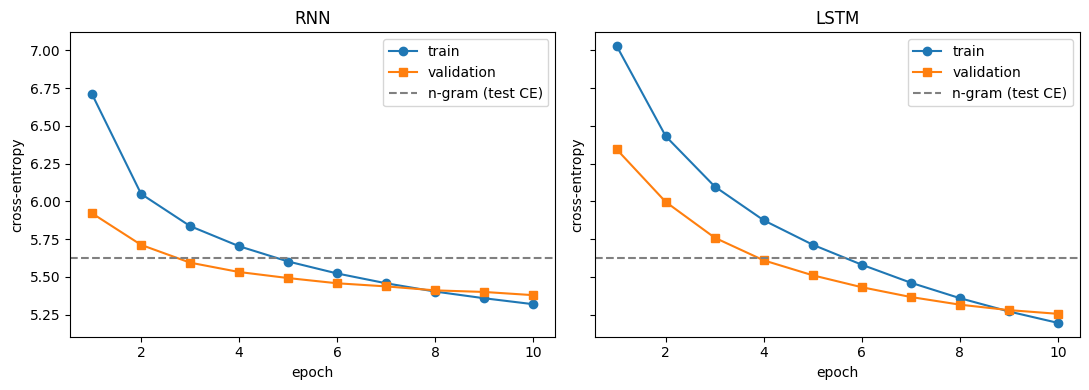

In [ ]:
#loss curves

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, h) in zip(axes, [("RNN", rnn_hist), ("LSTM", lstm_hist)]):
    ep = range(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], "o-", label="train")
    ax.plot(ep, h["val_loss"], "s-", label="validation")
    ax.axhline(results["ngram"]["test_ce"], ls="--", c="gray", label="n-gram (test CE)")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "curves_rnn_lstm.png"), dpi=150)
plt.show()


The grey dashed line is the n-gram's test cross-entropy, for reference.

In [ ]:
#final test scores

for name, model, h in [("rnn", rnn_model, rnn_hist), ("lstm", lstm_model, lstm_hist)]:
    test_ce = evaluate(model, test_data)
    results[name] = {
        "test_ce": test_ce,
        "test_ppl": math.exp(test_ce),
        "params": count_params(model),
        "train_time_s": sum(h["epoch_time"]),
        "best_epoch": int(np.argmin(h["val_loss"])) + 1,
    }
    print(name, json.dumps(results[name], indent=2))

with open(os.path.join(SAVE_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)


rnn {
  "test_ce": 5.300650972299062,
  "test_ppl": 200.46726614563752,
  "params": 10780436,
  "train_time_s": 411.27389907836914,
  "best_epoch": 10
}
lstm {
  "test_ce": 5.182850875844489,
  "test_ppl": 178.19008537176987,
  "params": 11450132,
  "train_time_s": 478.29659938812256,
  "best_epoch": 10
}


Each model's best checkpoint is evaluated on the test set once (same as the n-gram) and added to `results.json`.

### First observations: RNN vs LSTM

| Model | Test PPL | Params | Train time (10 epochs) | Time per epoch |
|---|---|---|---|---|
| n-gram | 277.5 | 2.0M n-grams | 3.6 s | - |
| RNN | 200.5 | 10.8M | 411 s | ~41 s |
| LSTM | 178.2 | 11.5M | 478 s | ~48 s |

What I observed:
1. Both neural models beat the n-gram. The RNN has 28% lower perplexity and the LSTM 36% lower.
2. The LSTM beats the RNN (178.2 vs 200.5) with only 6% more parameters and 16% more training time.
3. The RNN is levelling off. Its validation loss goes 5.458, 5.437, 5.411, 5.400, 5.379 over epochs 6-10, and its train loss drops below its validation loss around epoch 8.
4. The LSTM is still improving at epoch 10 (validation loss 5.316, 5.280, 5.255 over the last three epochs).
5. In the early epochs the train loss is higher than the validation loss. This is because dropout is only on during training, and the train loss is averaged over the whole epoch while the validation loss is measured at the end of it.

Possible reasons (not tested):
* The LSTM's gates may let it use more of the 64-token context, while the RNN's hidden state fades. I didn't measure how much context each model actually uses.
* Both models had the same budget of 10 epochs, so this compares them at equal training time, not after they fully converge. The LSTM hadn't converged yet, so the gap could change with longer training.

## 6. The Transformer

Instead of squeezing the history into one hidden state, the Transformer looks directly at all previous tokens at every position (self-attention). It needs two extra pieces:
1. A causal mask, so each position can only look at itself and earlier positions and can't see the word it has to predict.
2. Positional embeddings, because attention has no sense of word order on its own. I add a learned vector for each position 0-63.

To keep it comparable with the RNN/LSTM:
* It uses the same 100-d random, trainable input embedding, followed by a linear layer from 100 to 256 so the model width matches the LSTM hidden size.
* It has the same 2 layers, dropout 0.3 and output layer (256 to 29,572), so the parameter count is similar (11.65M vs 11.45M for the LSTM).
* It is trained with the same 10 epochs, learning rate, batches and 64-token context.

In [ ]:
#the transformer model
class TransformerLM(nn.Module):
    def __init__(self, vocab_size, emb_dim=EMB_DIM, d_model=HIDDEN_DIM, nhead=4,
                 num_layers=NUM_LAYERS, ff_dim=512, dropout=DROPOUT, max_len=BPTT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)     # word -> 100 numbers
        self.in_proj = nn.Linear(emb_dim, d_model)              # 100 -> 256
        self.pos = nn.Embedding(max_len, d_model)               # position 0..63 -> 256 numbers
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff_dim, dropout,
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, vocab_size)                # 256 -> score per word

    def forward(self, x):
        T = x.size(1)
        positions = torch.arange(T, device=x.device)
        h = self.in_proj(self.drop(self.embedding(x))) + self.pos(positions)
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)  # causal mask
        h = self.encoder(self.drop(h), mask=mask, is_causal=True)
        return self.fc(self.drop(h))


Notes on the Transformer:
* `nhead=4`: four attention heads run in parallel.
* `ff_dim=512`: size of the feed-forward layer after attention.
* `generate_square_subsequent_mask(T)` makes a T × T mask where position i can only attend to positions 0 to i. Future positions are set to −∞, so they get zero attention.
* `norm_first=True` puts the LayerNorm before each sub-layer (pre-LN), which is more stable for small Transformers, and there is a final LayerNorm after the last layer.

In [ ]:
#prove the model cannot see the future
set_seed()
m = TransformerLM(V).to(device).eval()
print(f"Transformer params = {count_params(m):,}")

x, _ = get_batch(train_data, 0)
x2 = x.clone()
x2[:, 40] = (x2[:, 40] + 1) % V          # change ONLY the word at position 40

with torch.no_grad():
    a, b = m(x), m(x2)

print("Outputs at positions 0–39 unchanged:", torch.allclose(a[:, :40], b[:, :40], atol=1e-5))
print("Outputs at positions 40+ changed:   ", not torch.allclose(a[:, 40:], b[:, 40:]))


Transformer params = 11,654,164
Outputs at positions 0–39 unchanged: True
Outputs at positions 40+ changed:    True


**Causality check:** I changed only the token at position 40. The outputs at positions 0-39 stay exactly the same and the outputs from position 40 onwards change, so each prediction only uses the tokens before it.

In [ ]:
#train it
set_seed()
tf_model = TransformerLM(V)
tf_hist = train_or_load(tf_model, "transformer")


Loaded saved transformer (skipping training)


The Transformer uses the same `train_model` function and settings as the RNN and LSTM.

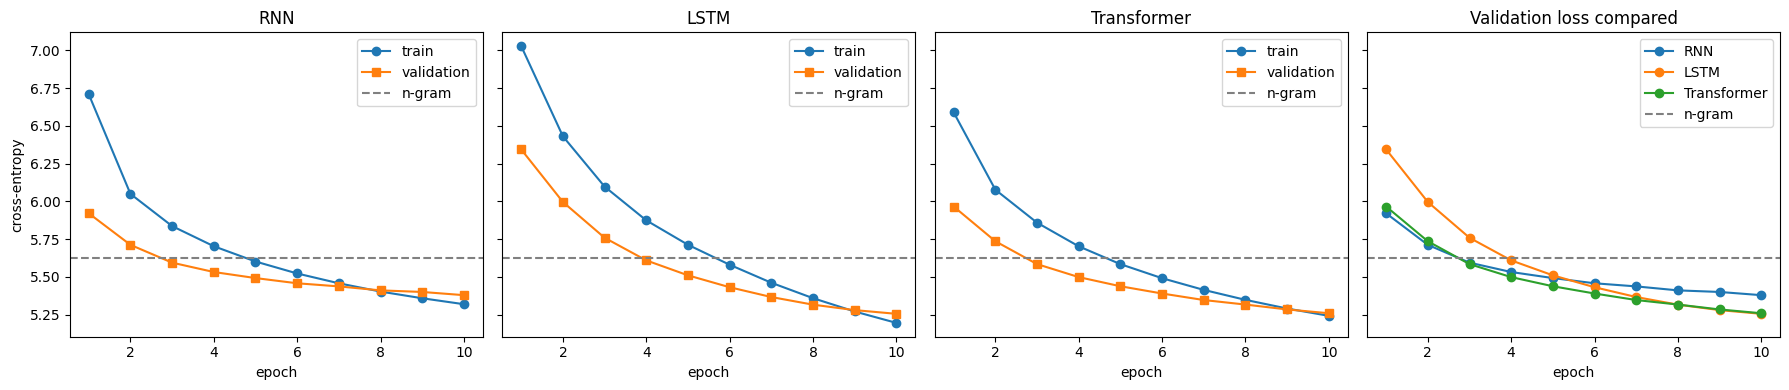

{
  "test_ce": 5.180286400718584,
  "test_ppl": 177.73370676605805,
  "params": 11654164,
  "train_time_s": 435.1860456466675,
  "best_epoch": 10
}


In [ ]:
#curves for all three neural models, plus the Transformer's test score
hists = {"RNN": rnn_hist, "LSTM": lstm_hist, "Transformer": tf_hist}

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, h) in zip(axes[:3], hists.items()):
    ep = range(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], "o-", label="train")
    ax.plot(ep, h["val_loss"], "s-", label="validation")
    ax.axhline(results["ngram"]["test_ce"], ls="--", c="gray", label="n-gram")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("cross-entropy")
for name, h in hists.items():                               # 4th panel: validation curves together
    axes[3].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], "o-", label=name)
axes[3].axhline(results["ngram"]["test_ce"], ls="--", c="gray", label="n-gram")
axes[3].set_title("Validation loss compared"); axes[3].set_xlabel("epoch"); axes[3].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "curves_all.png"), dpi=150)
plt.show()

test_ce = evaluate(tf_model, test_data)
results["transformer"] = {
    "test_ce": test_ce,
    "test_ppl": math.exp(test_ce),
    "params": count_params(tf_model),
    "train_time_s": sum(tf_hist["epoch_time"]),
    "best_epoch": int(np.argmin(tf_hist["val_loss"])) + 1,
}
print(json.dumps(results["transformer"], indent=2))
with open(os.path.join(SAVE_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)


## 7. Inference cost

In [ ]:
#measure throughput and build the part 1 results table
import pandas as pd

def measure_inference(model, data, runs=3):
    model.eval()
    evaluate(model, data)                                  # warm-up run (not timed)
    times = []
    for _ in range(runs):
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        evaluate(model, data)
        if device == "cuda": torch.cuda.synchronize()
        times.append(time.time() - t0)
    n_tokens = data.size(0) * (data.size(1) - 1)
    avg = float(np.mean(times))
    return avg, n_tokens / avg

for name, model in [("rnn", rnn_model), ("lstm", lstm_model), ("transformer", tf_model)]:
    if REUSE_SAVED and "infer_time_s" in saved_results.get(name, {}):
        t, tput = saved_results[name]["infer_time_s"], saved_results[name]["throughput_tok_per_s"]
    else:
        t, tput = measure_inference(model, test_data)
    results[name]["infer_time_s"] = t
    results[name]["throughput_tok_per_s"] = tput

hardware = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"
print("Hardware:", hardware)

table = pd.DataFrame({
    name: {
        "Test PPL": round(r["test_ppl"], 1),
        "Test CE": round(r["test_ce"], 3),
        "Params / n-grams": r.get("params", r.get("size_num_ngrams")),
        "Train time (s)": round(r["train_time_s"], 1),
        "Test inference (s)": round(r["infer_time_s"], 2),
        "Throughput (tok/s)": int(r["throughput_tok_per_s"]),
    } for name, r in results.items()
}).T
print(table)

with open(os.path.join(SAVE_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)
table.to_csv(os.path.join(SAVE_DIR, "part1_table.csv"))


Hardware: Tesla T4
             Test PPL  Test CE  Params / n-grams  Train time (s)  \
ngram           277.5    5.626         2014882.0             6.2   
rnn             200.5    5.301        10780436.0           411.3   
lstm            178.2    5.183        11450132.0           478.3   
transformer     177.7    5.180        11654164.0           435.2   

             Test inference (s)  Throughput (tok/s)  
ngram                      0.53            463855.0  
rnn                        1.68            145408.0  
lstm                       1.88            129544.0  
transformer                1.78            136929.0  


How I measured inference cost:
* The common workload is scoring every test token with `evaluate` (batch 32, 64-token windows), with the same function, data and batch size for all neural models.
* I do one warm-up run that isn't timed, then take the average of 3 timed runs, with `torch.cuda.synchronize()` before and after each run.
* Throughput is the number of test tokens scored per second (higher is faster).
* Hardware: Tesla T4 on Google Colab. The n-gram runs on the CPU using Python dictionary lookups while the neural models run on the GPU, so the n-gram's speed can't be compared directly with theirs.

## 8. Text generation

I use the same decoding settings for all four models:
* 5 prompts, 30 generated tokens each.
* Sampling with temperature 0.8 and top-k 40, using seed 42 + prompt number (the same for every model).
* Greedy decoding (always pick the most likely word) as a second setting.
* `<unk>` is never generated (its score is set to −∞ for every model).
* The neural models only see the last 64 tokens (same as in training) and the n-gram uses its last 2.

In [ ]:
#next word functions for the n-gram and neural models
from collections import defaultdict

# --- n-gram: build "what follows this context" lookups ---
bi_next = defaultdict(dict)
for (u, w), c in bi.items():
    bi_next[u][w] = c
tri_next = defaultdict(dict)
for (t, u, w), c in tri.items():
    tri_next[(t, u)][w] = c
uni_prob = torch.tensor([(uni[i] + 1) / (N + V) for i in range(V)], dtype=torch.float)

def ngram_next_logits(ids):
    l1, l2, l3 = best_lambdas
    p = l1 * uni_prob.clone()
    t, u = ids[-2], ids[-1]
    if ctx1[u] > 0:
        for w, c in bi_next[u].items():
            p[w] += l2 * c / ctx1[u]
    if ctx2[(t, u)] > 0:
        for w, c in tri_next[(t, u)].items():
            p[w] += l3 * c / ctx2[(t, u)]
    return torch.log(p)

# --- neural models: run the last 64 words, take the scores at the final position ---
@torch.no_grad()
def neural_next_logits(model, ids):
    model.eval()
    x = torch.tensor([ids[-BPTT:]], device=device)
    return model(x)[0, -1].float().cpu()


* n-gram: I build the full interpolated distribution over the vocabulary from the last 2 tokens (same formula and λ values as in evaluation) and take the log, so all four models can use the same sampling function.
* Neural models: I run the last 64 tokens through the model and take the scores at the final position.

In [ ]:
def sample_from_logits(logits, temperature=0.8, top_k=40, greedy=False, gen=None):
    logits = logits.clone()
    logits[stoi["<unk>"]] = -float("inf")          # never generate <unk>
    if greedy:
        return int(torch.argmax(logits))
    vals, idx = torch.topk(logits / temperature, top_k)
    probs = torch.softmax(vals, dim=-1)
    return int(idx[torch.multinomial(probs, 1, generator=gen)])

def generate(next_logits_fn, prompt, n_words=30, greedy=False, seed=SEED):
    gen = torch.Generator().manual_seed(seed)
    ids = encode(prompt.lower().split())
    for _ in range(n_words):
        ids.append(sample_from_logits(next_logits_fn(ids), greedy=greedy, gen=gen))
    return " ".join(itos[i] for i in ids)


In [ ]:
prompts = [
    "the city of",
    "in 1990 , the",
    "the game was released",
    "he was born in",
    "the album received",
]

generators = {
    "n-gram":      ngram_next_logits,
    "RNN":         lambda ids: neural_next_logits(rnn_model, ids),
    "LSTM":        lambda ids: neural_next_logits(lstm_model, ids),
    "Transformer": lambda ids: neural_next_logits(tf_model, ids),
}

lines = []
for mode in ["sampling (T=0.8, top-k=40)", "greedy"]:
    lines.append(f"\n########## {mode} ##########")
    for p_i, prompt in enumerate(prompts):
        lines.append(f"\nPROMPT: {prompt}")
        for name, fn in generators.items():
            text = generate(fn, prompt, greedy=(mode == "greedy"), seed=SEED + p_i)
            lines.append(f"  [{name:11s}] {text}")

output = "\n".join(lines)
print(output)
with open(os.path.join(SAVE_DIR, "generations.txt"), "w", encoding="utf-8") as f:
    f.write(output)



########## sampling (T=0.8, top-k=40) ##########

PROMPT: the city of
  [n-gram     ] the city of the season was . <eos> and the = = that and was the the more " . the " , she was a of bella center and a the the
  [RNN        ] the city of the pacific ocean ( the southern terminus from september 17 , 2005 ) . a storm of the area is more than 1 @.@ 4 m ☉ , and the
  [LSTM       ] the city of the northern union . the area was demolished . when the company was a new american force , the fort remained in the early 20th century , which was the
  [Transformer] the city of the central terminus . the missouri river were known locally known as the missouri and was the first creek was recorded to the eastern terminus of central pacific ocean .

PROMPT: in 1990 , the
  [n-gram     ] in 1990 , the second album , " it was a , which a local of the album was created to the first part of the the today ) the the , in a
  [RNN        ] in 1990 , the area was a first largest @-@ class area at the univers

Every model gets the same prompt, seed, length and decoding rule, so only the model changes. All the outputs are saved to `generations.txt`.

## 9. Part I summary

**Prediction quality**

| Model | Test PPL | Test CE |
|---|---|---|
| Interpolated trigram | 277.5 | 5.626 |
| RNN | 200.5 | 5.301 |
| LSTM | 178.2 | 5.183 |
| Transformer | 177.7 | 5.180 |

All the neural models beat the n-gram. The LSTM and Transformer are basically tied: 0.5 perplexity apart from a single seed is too small to call a winner, so I treat them as comparable. Both clearly beat the RNN. My guess is that with only 64 tokens of context and about 11M parameters, the Transformer's direct access to every previous token doesn't have much room to help, and the RNN's weaker result fits with its hidden state fading across the window.

**Learning behaviour** (`curves_all.png`)
* The Transformer has the lowest validation loss early on (epoch 1: 5.97 vs 6.34 for the LSTM) and goes below the n-gram's test cross-entropy by epoch 3.
* The LSTM starts slowest and catches up with the Transformer around epoch 8.
* The RNN levels off after about epoch 6, and its train loss drops below its validation loss (early overfitting).
* The LSTM and Transformer are still improving at epoch 10, and the best checkpoint is epoch 10 for all three. So my ranking is for a 10-epoch budget, not for fully trained models. Dropout 0.3 keeps overfitting small.

**Cost** (Tesla T4)

| Model | Params | Train time | Throughput (tok/s) |
|---|---|---|---|
| n-gram | 2.0M n-grams | 3.6 s (CPU) | 497k (CPU) |
| RNN | 10.8M | 411 s | 146k |
| LSTM | 11.5M | 478 s | 114k |
| Transformer | 11.7M | 435 s | 142k |

* The Transformer is faster than the LSTM in both training (about 44 vs 48 s per epoch) and inference (142k vs 114k tok/s), even with slightly more parameters. I think this is because attention handles all 64 positions in parallel, while the LSTM has to step through them one by one.
* The n-gram is about 100 times cheaper to train but its perplexity is 36% higher than the LSTM's.

**Generated text** (`generations.txt`)
* With greedy decoding every model ends up repeating itself. The n-gram gets stuck in an exact loop ("the the grand slam tournament , and the the grand slam tournament ..."). This has to happen for a greedy trigram: its only state is the last 2 tokens, so once a pair repeats, the output cycles forever. The neural models loop on common phrases ("the first time of the first time", "the city of the city of") and on heading markup ("= = = ="), which is the most common trigram in the training data.
* With sampling, the n-gram produces broken phrases with doubled function words ("a the the", "the and the"). My guess is that the 0.30 unigram weight keeps giving frequent words a high probability no matter the context.
* The neural models are more fluent locally ("the fort remained in the early 20th century" from the LSTM, "at number 11 of the billboard hot 100" from the Transformer), but they all drift off topic within 30 tokens. For example, the Transformer's "in 1990" continuation turns into a description of a hurricane.
* Five prompts is a small sample, so I only use these to illustrate the differences, not to rank the models.

**Overall:** the neural models lower perplexity by 28-36% compared to the interpolated trigram, at roughly 100 times the training cost. The LSTM and Transformer reach similar perplexity with 10 epochs, with the Transformer being faster to train and run, while the RNN levels off earlier. All models degenerate with greedy decoding, the n-gram the worst because its 2-token state forces it into loops.